In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

f = pd.read_parquet("../data/interim/flows_long")
print(f.shape, "| entreprises :", f["cik"].nunique())
print(f["concept"].value_counts())
f.head()

(2397983, 10) | entreprises : 14039
concept
NetIncomeLoss                                          466862
OperatingIncomeLoss                                    313381
NetCashProvidedByUsedInOperatingActivities             220340
NetCashProvidedByUsedInFinancingActivities             216985
Revenues                                               202972
NetCashProvidedByUsedInInvestingActivities             200018
InterestExpense                                        181607
PaymentsToAcquirePropertyPlantAndEquipment             160277
DepreciationDepletionAndAmortization                   124597
SalesRevenueNet                                         94314
PaymentsForRepurchaseOfCommonStock                      94247
RevenueFromContractWithCustomerExcludingAssessedTax     83678
PaymentsOfDividends                                     38705
Name: count, dtype: int64


,cik,concept,val,start,end,filed,form,fy,fp,accn
0,0000001750,DepreciationDepletionAndAmortization,40094000.0,2008-06-01,2009-05-31,2011-07-13,10-K,2011,FY,0001047469-11-006302
1,0000001750,DepreciationDepletionAndAmortization,38930000.0,2009-06-01,2010-05-31,2011-07-13,10-K,2011,FY,0001047469-11-006302
2,0000001750,DepreciationDepletionAndAmortization,38930000.0,2009-06-01,2010-05-31,2012-07-19,10-K,2012,FY,0001047469-12-007300
3,0000001750,DepreciationDepletionAndAmortization,59296000.0,2010-06-01,2011-05-31,2011-07-13,10-K,2011,FY,0001047469-11-006302
4,0000001750,DepreciationDepletionAndAmortization,59296000.0,2010-06-01,2011-05-31,2012-07-19,10-K,2012,FY,0001047469-12-007300


count    2.396984e+06
mean     3.174738e+02
std      3.202955e+02
min      1.000000e+00
25%      3.630000e+02
50%      3.640000e+02
75%      3.640000e+02
max      6.829900e+04
Name: duree, dtype: float64


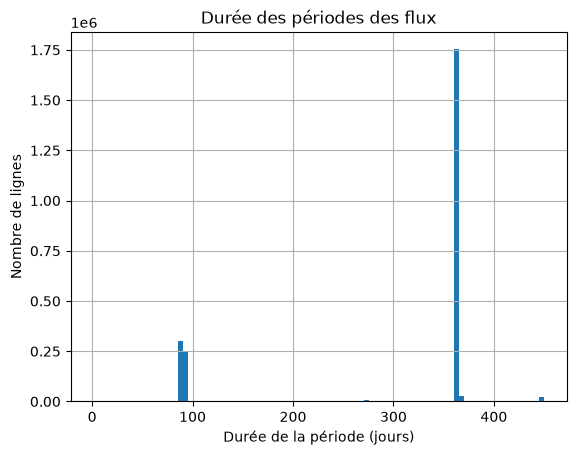

Périodes d'environ 1 an (350-380 j) : 74.3%


In [2]:
f["duree"] = (f["end"] - f["start"]).dt.days
print(f["duree"].describe())

f["duree"].clip(0, 450).hist(bins=90)
plt.xlabel("Durée de la période (jours)"); plt.ylabel("Nombre de lignes")
plt.title("Durée des périodes des flux"); plt.show()

print(f"Périodes d'environ 1 an (350-380 j) : {f['duree'].between(350, 380).mean():.1%}")

In [3]:
ecart = (f["filed"] - f["end"]).dt.days
d = f[f["duree"].between(350, 380) & ecart.between(0, 550)].copy()
print(f"Lignes gardées : {len(d):,} ({len(d)/len(f):.1%})")

Lignes gardées : 1,324,226 (55.2%)


In [4]:
d = d.sort_values(["cik", "concept", "end", "filed", "accn"])
d = d.drop_duplicates(subset=["cik", "concept", "end"], keep="first")
print(f"Lignes : {len(d):,} | doublons restants :",
      d.duplicated(subset=["cik", "concept", "end"]).sum())

Lignes : 762,942 | doublons restants : 0


In [5]:
fw = d.pivot(index=["cik", "end"], columns="concept", values="val")
fw.columns.name = None
fw = fw.reset_index()
print(fw.shape)

(105931, 15)


In [6]:
ca_cols = [c for c in ["Revenues",
                       "RevenueFromContractWithCustomerExcludingAssessedTax",
                       "SalesRevenueNet"] if c in fw]
fw["CA"] = fw[ca_cols[0]]
for c in ca_cols[1:]:
    fw["CA"] = fw["CA"].fillna(fw[c])          # on complète avec l'étiquette suivante

for c in ca_cols + ["CA"]:
    print(f"{c:<55} {fw[c].notna().mean():.1%}")

Revenues                                                43.0%
RevenueFromContractWithCustomerExcludingAssessedTax     22.5%
SalesRevenueNet                                         15.1%
CA                                                      70.8%


In [7]:
w = pd.read_parquet("../data/interim/balance_sheet_wide.parquet")
m = w[["cik", "end"]].merge(fw, on=["cik", "end"], how="left", indicator=True)
print(m["_merge"].value_counts(normalize=True).round(3))

flux = [c for c in fw if c not in ("cik", "end")]
print("\nCouverture de chaque flux, sur les bilans :")
print(m[flux].notna().mean().sort_values(ascending=False).round(3))

_merge
both          0.971
left_only     0.029
right_only    0.000
Name: proportion, dtype: float64

Couverture de chaque flux, sur les bilans :
NetIncomeLoss                                          0.905
NetCashProvidedByUsedInOperatingActivities             0.855
NetCashProvidedByUsedInFinancingActivities             0.843
NetCashProvidedByUsedInInvestingActivities             0.780
OperatingIncomeLoss                                    0.746
CA                                                     0.693
PaymentsToAcquirePropertyPlantAndEquipment             0.608
InterestExpense                                        0.575
DepreciationDepletionAndAmortization                   0.461
Revenues                                               0.420
PaymentsForRepurchaseOfCommonStock                     0.344
RevenueFromContractWithCustomerExcludingAssessedTax    0.221
SalesRevenueNet                                        0.148
PaymentsOfDividends                                    0.137
d

In [8]:
fw.to_parquet("../data/interim/flows_wide.parquet", index=False)